# ASA Conecta — Entrega 2 (Final): avaliação, explicabilidade e inferência
**Agente para o Estudante / Monitoramento de risco de evasão** · versão do modelo `1.0.0`

Este notebook reproduz de ponta a ponta: (1) qualidade dos dados, (2) comparação de modelos com validação cruzada,
(3) escolha justificada, (4) limiares e faixas de risco, (5) teste de dependência/vazamento por ablação de atributos,
(6) equidade por subgrupo, (7) análise de erros, (8) explicabilidade, (9) versionamento e artefato de inferência.

Dados: `base_unificada_asa-final.csv` (na mesma pasta). Semente fixa `42`. Todas as tabelas e figuras são salvas em `resultados/`.

In [1]:
import os, json, hashlib, warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve)
warnings.filterwarnings("ignore")
SEED, DATA, OUT = 42, "base_unificada_asa-final.csv", "resultados"
os.makedirs(OUT, exist_ok=True); os.makedirs("modelo", exist_ok=True)

raw = pd.read_csv(DATA)
df = raw.dropna(subset=["evadiu"]).copy()
df["evadiu"] = df["evadiu"].astype(int); df["tem_bolsa"] = df["tem_bolsa"].astype(int)
print(f"Linhas no arquivo: {len(raw)} | com rótulo: {len(df)} | IDs únicos: {df.ID_ALUNO.nunique()} (repetidos: {len(df)-df.ID_ALUNO.nunique()})")
print(f"Evasão: {df.evadiu.sum()} ({df.evadiu.mean():.1%}) | sha256 da base: {hashlib.sha256(open(DATA,'rb').read()).hexdigest()[:16]}")
aus = df.isna().sum()[lambda s: s>0]; print("\nColunas com valores ausentes:", "nenhuma" if aus.empty else aus.to_dict())
print("\nAlunos sem nenhum semestre de histórico (total_semestres==0):", f"{(df.total_semestres==0).mean():.1%}",
      "| taxa de evasão neles:", f"{df[df.total_semestres==0].evadiu.mean():.1%}", "vs", f"{df[df.total_semestres>0].evadiu.mean():.1%}", "nos demais")

Linhas no arquivo: 12842 | com rótulo: 12842 | IDs únicos: 12835 (repetidos: 7)
Evasão: 2512 (19.6%) | sha256 da base: 3bd8ed7d31b40c1f

Colunas com valores ausentes: nenhuma

Alunos sem nenhum semestre de histórico (total_semestres==0): 40.9% | taxa de evasão neles: 31.4% vs 11.4% nos demais


## 1. Comparação de modelos
Quatro candidatos mais um *baseline* trivial. Todos usam o mesmo *holdout* estratificado 80/20 (`random_state=42`, igual à Entrega 1)
e validação cruzada estratificada de 5 *folds* **somente no treino**. Como a classe positiva é minoritária (~19,6%), a métrica de decisão é a **PR-AUC**
(média no CV), com ROC-AUC, precisão/recall/F1, Brier (calibração) e precisão no topo do ranking (P@10% e P@20%).

`Random Forest sem Sexo/Estado Civil` é a mesma configuração da Random Forest, sem os dois atributos pessoais, para testar se eles são necessários (seção 5).

In [2]:
SENS = ["Sexo", "Estado Civil"]                      # atributos pessoais cuja necessidade é testada
features = [c for c in df.columns if c not in ["ID_ALUNO", "evadiu"]]
is_cat = lambda c: df[c].dtype == "object" or str(df[c].dtype) == "str"
X, y = df[features], df["evadiu"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.20, stratify=y, random_state=SEED)

def prep(cols, scale):
    num = [c for c in cols if not is_cat(c)]; cat = [c for c in cols if is_cat(c)]
    n = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    c = [("imp", SimpleImputer(strategy="most_frequent")),
         ("enc", OneHotEncoder(handle_unknown="ignore") if scale else OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))]
    return ColumnTransformer([("num", Pipeline(n), num), ("cat", Pipeline(c), cat)])

RF = lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
HGB = lambda: HistGradientBoostingClassifier(max_depth=4, learning_rate=.06, max_iter=250, class_weight="balanced", random_state=SEED)
no_sens = [c for c in features if c not in SENS]
models = {
    "Baseline (classe majoritária)": Pipeline([("p", prep(features, True)), ("m", DummyClassifier(strategy="prior"))]),
    "Regressão Logística":           Pipeline([("p", prep(features, True)), ("m", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))]),
    "Random Forest":                 Pipeline([("p", prep(features, False)), ("m", RF())]),
    "Gradient Boosting (HistGB)":    Pipeline([("p", prep(features, False)), ("m", HGB())]),
    "Random Forest sem Sexo/Estado Civil": Pipeline([("p", prep(no_sens, False)), ("m", RF())]),
}
def prec_at(yt, s, frac):
    k = max(1, int(len(s)*frac)); return yt.values[np.argsort(-s)[:k]].mean()
def metrics(yt, p, thr=.5):
    pr = (p >= thr).astype(int)
    return dict(roc_auc=roc_auc_score(yt, p), pr_auc=average_precision_score(yt, p), precision=precision_score(yt, pr, zero_division=0),
                recall=recall_score(yt, pr), f1=f1_score(yt, pr), brier=brier_score_loss(yt, p),
                p_at_10=prec_at(yt, p, .10), p_at_20=prec_at(yt, p, .20))
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows, probs = [], {}
for name, m in models.items():
    cv = cross_validate(m, Xtr, ytr, cv=skf, scoring=["roc_auc", "average_precision", "f1", "recall"])
    m.fit(Xtr, ytr); probs[name] = m.predict_proba(Xte)[:, 1]
    rows.append(dict(modelo=name, **metrics(yte, probs[name]), cv_roc_auc=cv["test_roc_auc"].mean(), cv_roc_auc_dp=cv["test_roc_auc"].std(),
                     cv_pr_auc=cv["test_average_precision"].mean(), cv_pr_auc_dp=cv["test_average_precision"].std(), cv_f1=cv["test_f1"].mean(), cv_recall=cv["test_recall"].mean()))
comp = pd.DataFrame(rows); comp.to_csv(f"{OUT}/comparacao_modelos.csv", index=False)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
print("Teste (limiar 0,50) e validação cruzada (5 folds, treino):")
print(comp.round(3).to_string(index=False))

Teste (limiar 0,50) e validação cruzada (5 folds, treino):
                             modelo  roc_auc  pr_auc  precision  recall    f1  brier  p_at_10  p_at_20  cv_roc_auc  cv_roc_auc_dp  cv_pr_auc  cv_pr_auc_dp  cv_f1  cv_recall
      Baseline (classe majoritária)    0.500   0.196      0.000   0.000 0.000  0.157    0.168    0.201       0.500          0.000      0.196         0.000  0.000      0.000
                Regressão Logística    0.814   0.562      0.413   0.777 0.540  0.173    0.680    0.561       0.836          0.010      0.602         0.018  0.549      0.791
                      Random Forest    0.927   0.822      0.742   0.726 0.734  0.082    0.934    0.727       0.937          0.009      0.849         0.021  0.758      0.757
         Gradient Boosting (HistGB)    0.915   0.791      0.654   0.771 0.708  0.099    0.895    0.712       0.929          0.008      0.834         0.022  0.745      0.805
Random Forest sem Sexo/Estado Civil    0.927   0.826      0.739   0.738 0.73

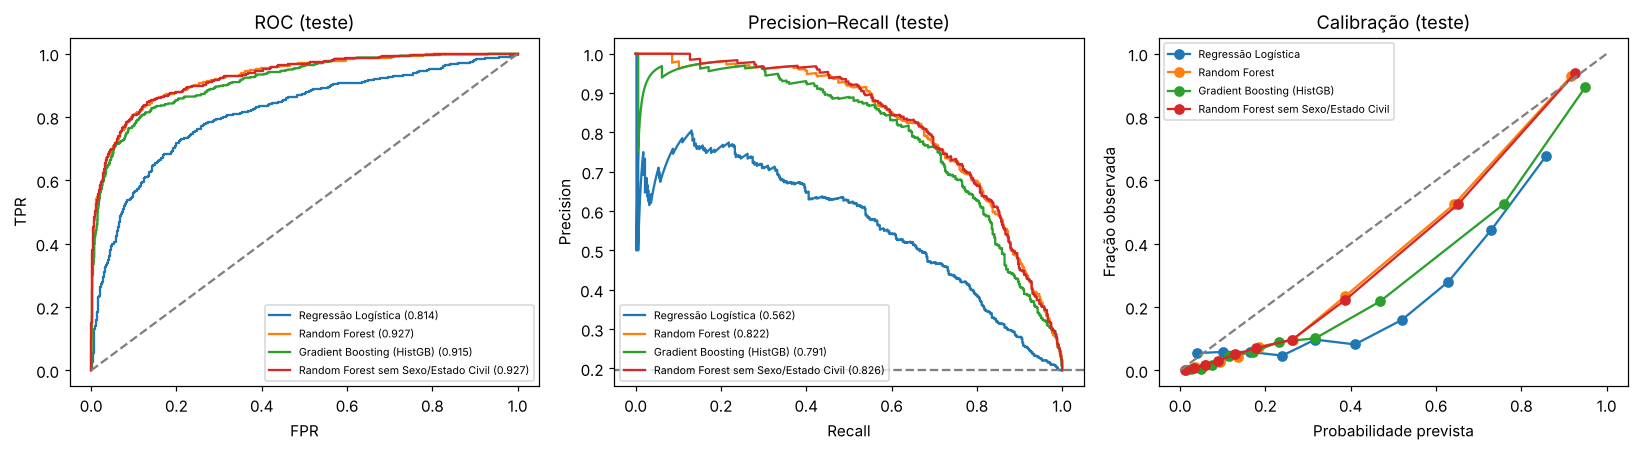

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for n, p in probs.items():
    if n.startswith("Baseline"): continue
    f, t, _ = roc_curve(yte, p); ax[0].plot(f, t, label=f"{n} ({roc_auc_score(yte, p):.3f})")
    pr, rc, _ = precision_recall_curve(yte, p); ax[1].plot(rc, pr, label=f"{n} ({average_precision_score(yte, p):.3f})")
    fr, mp = calibration_curve(yte, p, n_bins=10, strategy="quantile"); ax[2].plot(mp, fr, "o-", label=n)
ax[0].plot([0,1],[0,1],"--",c="gray"); ax[0].set(title="ROC (teste)", xlabel="FPR", ylabel="TPR")
ax[1].axhline(yte.mean(), ls="--", c="gray"); ax[1].set(title="Precision–Recall (teste)", xlabel="Recall", ylabel="Precision")
ax[2].plot([0,1],[0,1],"--",c="gray"); ax[2].set(title="Calibração (teste)", xlabel="Probabilidade prevista", ylabel="Fração observada")
for a in ax: a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/curvas_roc_pr_calibracao.png", dpi=140); plt.show()

### Escolha
**Random Forest sem Sexo/Estado Civil** é o modelo final.
(i) As Random Forests superam a Regressão Logística com folga (PR-AUC no CV de ~0,85 contra ~0,60, muito acima do desvio entre *folds* de ~0,02).
(ii) Contra o Gradient Boosting a diferença em PR-AUC no CV é pequena (~0,017, dentro do desvio entre *folds*): é um **empate técnico**. O desempate foi pelo menor Brier (0,081 contra 0,099), pela maior precisão no topo do ranking (P@10% 0,94 contra 0,90) e pela configuração mais simples; o Gradient Boosting tem recall um pouco maior em limiar 0,50.
(iii) Retirar Sexo e Estado Civil não reduz o desempenho (comparação direta na tabela acima e na análise de equidade), então não há ganho preditivo que justifique usar esses atributos pessoais.
A Regressão Logística segue como referência interpretável (coeficientes), com PR-AUC ~0,25 menor.

 limiar  precision  recall    f1  alertas_pct   FP  FN
   0.10      0.309   0.974 0.469        0.618 1097  13
   0.15      0.370   0.946 0.532        0.501  811  27
   0.20      0.432   0.917 0.587        0.416  607  42
   0.25      0.485   0.895 0.629        0.361  478  53
   0.30      0.543   0.867 0.668        0.313  367  67
   0.35      0.611   0.843 0.708        0.270  270  79
   0.40      0.661   0.807 0.727        0.239  208  97
   0.45      0.704   0.771 0.736        0.214  163 115
   0.50      0.739   0.738 0.738        0.195  131 132
   0.55      0.773   0.698 0.734        0.177  103 152
   0.60      0.809   0.674 0.735        0.163   80 164
   0.65      0.834   0.628 0.717        0.148   63 187
   0.70      0.857   0.596 0.703        0.136   50 203
   0.75      0.881   0.557 0.682        0.124   38 223
   0.80      0.922   0.517 0.662        0.110   22 243
   0.85      0.946   0.453 0.613        0.094   13 275
   0.90      0.967   0.346 0.510        0.070    6 329

Faixas de

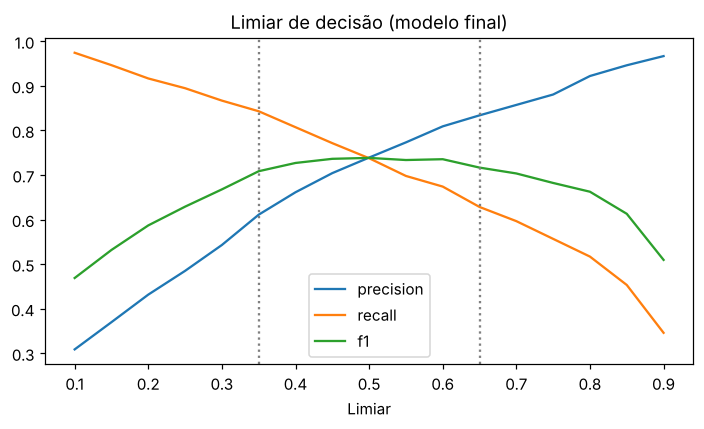

In [4]:
FINAL = "Random Forest sem Sexo/Estado Civil"
final = models[FINAL]; pf = probs[FINAL]; FEATS = no_sens
rows = []
for t in np.round(np.arange(.10, .91, .05), 2):
    pr = (pf >= t).astype(int); tn, fp, fn, tp = confusion_matrix(yte, pr).ravel()
    rows.append(dict(limiar=t, precision=tp/max(tp+fp,1), recall=tp/(tp+fn), f1=f1_score(yte, pr), alertas_pct=pr.mean(), FP=fp, FN=fn))
thr = pd.DataFrame(rows); thr.to_csv(f"{OUT}/analise_limiares.csv", index=False)
print(thr.round(3).to_string(index=False))
bands = pd.cut(pf, [-.01, .35, .65, 1.01], labels=["Verde (<0,35)", "Amarelo (0,35–0,65)", "Vermelho (≥0,65)"])
faixa = pd.DataFrame({"faixa": bands, "y": yte.values}).groupby("faixa", observed=False).agg(alunos=("y","size"), evadiram=("y","sum"), taxa_evasao=("y","mean")).reset_index()
faixa["pct_do_teste"] = faixa.alunos / faixa.alunos.sum(); faixa.to_csv(f"{OUT}/faixas_risco.csv", index=False)
print("\nFaixas de risco (mesmos cortes 0,35/0,65 do protótipo da Entrega 1):"); print(faixa.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(6.5, 4)); [ax.plot(thr.limiar, thr[c], label=c) for c in ["precision","recall","f1"]]
ax.axvline(.35, ls=":", c="gray"); ax.axvline(.65, ls=":", c="gray"); ax.set(title="Limiar de decisão (modelo final)", xlabel="Limiar"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/limiares.png", dpi=140); plt.show()

### Limiares
Os cortes 0,35 e 0,65 do protótipo foram **mantidos**: com o modelo final as faixas ficam monotônicas e bem separadas (taxa de evasão observada crescente de Verde a Vermelho),
e cada corte tem uma função distinta, em vez de um único limiar:
**≥ 0,65 (Vermelho)** → fila de revisão humana prioritária (maior precisão); **≥ 0,35** → ampla rede de acompanhamento (maior recall, útil porque falso negativo significa aluno sem apoio).

## 2. Dependência de atributos (ablação) — checagem de vazamento
A Random Forest passa de ROC-AUC 0,81 (Regressão Logística) para ~0,93. Antes de aceitar esse ganho, testamos de onde ele vem, retirando grupos de atributos.
Se o desempenho depender de atributos que só existem **depois** do desfecho (ex.: valor/parcelas acumulados de quem já saiu), o ganho é inflado.

In [5]:
fin  = ["total_parcelas","pct_parcelas_em_aberto","pct_parcelas_acordo","atraso_medio_dias","tem_bolsa","valor_total_periodo"]
hist = ["media_notas","media_assiduidade","pct_reprovacao","tendencia_notas","tendencia_assiduidade","total_semestres"]
rel  = ["total_contatos","dias_desde_ultimo_contato"]
cen = {"Modelo final (todas as features sem Sexo/Est. civil)": [], "Sem valor_total_periodo": ["valor_total_periodo"], "Sem financeiro": fin,
       "Sem histórico acadêmico": hist, "Sem relacionamento": rel, "Sem tempo_de_curso e total_semestres": ["tempo_de_curso","total_semestres"],
       "Sem financeiro e sem tempo/semestres": fin+["tempo_de_curso","total_semestres"], "Só matrícula/contexto": fin+hist+rel}
rows = []
for nome, drop in cen.items():
    fs = [c for c in FEATS if c not in drop]
    m = Pipeline([("p", prep(fs, False)), ("m", RF())]).fit(Xtr[fs], ytr); p = m.predict_proba(Xte[fs])[:, 1]
    rows.append(dict(cenario=nome, n_features=len(fs), roc_auc=roc_auc_score(yte, p), pr_auc=average_precision_score(yte, p)))
abl = pd.DataFrame(rows); abl.to_csv(f"{OUT}/ablacao_features.csv", index=False); print(abl.round(3).to_string(index=False))
print("\nMédias por desfecho:"); print(df.groupby("evadiu")[["valor_total_periodo","total_parcelas","tempo_de_curso","total_semestres"]].mean().round(1).to_string())
print("\nSplit por ID_ALUNO (sem aluno repetido entre treino e teste):")
from sklearn.model_selection import GroupShuffleSplit
tr, te = next(GroupShuffleSplit(1, test_size=.2, random_state=SEED).split(df, groups=df.ID_ALUNO))
m = Pipeline([("p", prep(FEATS, False)), ("m", RF())]).fit(df.iloc[tr][FEATS], df.iloc[tr].evadiu); p = m.predict_proba(df.iloc[te][FEATS])[:, 1]
print(f"ROC-AUC {roc_auc_score(df.iloc[te].evadiu, p):.3f} | PR-AUC {average_precision_score(df.iloc[te].evadiu, p):.3f}  (7 IDs repetidos na base; sem efeito material)")

                                             cenario  n_features  roc_auc  pr_auc
Modelo final (todas as features sem Sexo/Est. civil)          20    0.927   0.826
                             Sem valor_total_periodo          19    0.882   0.707
                                      Sem financeiro          14    0.842   0.598
                             Sem histórico acadêmico          14    0.921   0.817
                                  Sem relacionamento          18    0.921   0.799
                Sem tempo_de_curso e total_semestres          18    0.910   0.798
                Sem financeiro e sem tempo/semestres          12    0.811   0.562
                               Só matrícula/contexto           6    0.769   0.430

Médias por desfecho:
        valor_total_periodo  total_parcelas  tempo_de_curso  total_semestres
evadiu                                                                      
0                   50690.0            36.7             3.2              2.9
1        

**Leitura.** O ganho sobre a Regressão Logística depende em boa parte de `valor_total_periodo` e de tempo de curso/semestres. Sem financeiro e sem tempo/semestres o modelo cai para ~0,81 de ROC-AUC, o nível do baseline.
Quem evade tem valor acumulado e histórico bem menores (médias na saída acima), o que é compatível com um efeito mecânico (quem sai acumula menos) e não só com um sinal precoce de risco.
**Não é possível concluir, só com esta base, se `valor_total_periodo` foi medido antes ou depois da saída.** Isso é registrado como limitação principal no Model Card e como validação pendente com a área dona do dado
(a data de corte de cada atributo em relação à data da evasão).

## 3. Equidade por subgrupo

In [6]:
d = Xte[FEATS + SENS].copy(); d["y"] = yte.values; d["p"] = pf
d["Faixa etária"] = pd.cut(d.Idade, [0,20,25,30,40,200], labels=["≤20","21-25","26-30","31-40","40+"])
def grp(s, t):
    pr = (s.p >= t); pos = s.y == 1
    return pr.mean(), (pr[pos].mean() if pos.any() else np.nan), (pr[~pos].mean() if (~pos).any() else np.nan), (s.y[pr].mean() if pr.any() else np.nan)
rows = []
for g in ["Sexo","Turno","Forma de Ingresso","Grau Acadêmico","Faixa etária","tem_bolsa"]:
    for v, s in d.groupby(g, observed=True):
        if len(s) < 30: continue
        a35 = grp(s, .35); a65 = grp(s, .65)
        rows.append(dict(atributo=g, grupo=str(v), n=len(s), taxa_evasao=s.y.mean(), alerta_035=a35[0], recall_035=a35[1], fpr_035=a35[2], alerta_065=a65[0], recall_065=a65[1], precision_065=a65[3],
                         roc_auc=roc_auc_score(s.y, s.p) if 0 < s.y.sum() < len(s) else np.nan))
eq = pd.DataFrame(rows); eq.to_csv(f"{OUT}/equidade_subgrupos.csv", index=False)
print(eq.round(3).to_string(index=False))
print("\nMaiores diferenças de recall (limiar 0,35) entre grupos de mesmo atributo, n≥70:")
r = eq[eq.n >= 70].groupby("atributo").apply(lambda s: pd.Series(dict(pior=s.loc[s.recall_035.idxmin(),"grupo"], recall_pior=s.recall_035.min(), melhor=s.loc[s.recall_035.idxmax(),"grupo"], recall_melhor=s.recall_035.max())))
print(r.round(3).to_string())

         atributo                    grupo    n  taxa_evasao  alerta_035  recall_035  fpr_035  alerta_065  recall_065  precision_065  roc_auc
             Sexo                 Feminino 1344        0.190       0.260       0.859    0.119       0.140       0.641          0.872    0.936
             Sexo                Masculino 1147        0.206       0.285       0.822    0.146       0.158       0.610          0.796    0.914
             Sexo            Nao informado   78        0.141       0.231       0.909    0.119       0.128       0.727          0.800    0.976
            Turno                 Integral   87        0.253       0.322       0.773    0.169       0.126       0.455          0.909    0.880
            Turno                    Manhã 1656        0.153       0.203       0.834    0.089       0.108       0.617          0.872    0.939
            Turno                    Noite  826        0.276       0.400       0.860    0.224       0.229       0.658          0.794    0.902
Forma 

**Leitura.** Os grupos com mais alertas (Noite, Pós-graduação, Matrícula Inicial, 40+) são os que têm taxa real de evasão mais alta, então a taxa de alerta acompanha a taxa observada, o que não é por si só viés.
Dois pontos pedem atenção:
(1) **Carga de falsos alertas desigual.** Com limiar 0,35, a taxa de falsos positivos é de ~0,22 na Noite contra ~0,09 na Manhã, e ~0,28 entre 40+ contra ~0,05 entre ≤20: o custo de uma abordagem desnecessária recai mais sobre esses grupos.
(2) **Desempenho pior em grupos pequenos.** *Transferência Mesma Rede* (n=102) tem ROC-AUC 0,75, falso positivo de 0,40 e recall de apenas 0,20 no corte 0,65; *Integral* (n=87) e a faixa 26–30 têm recall menor (0,77 e 0,76 contra 0,84 no geral, limiar 0,35).
As amostras são pequenas e as estimativas têm intervalos largos; esses grupos devem ser monitorados antes de qualquer uso operacional. Sexo e Estado Civil foram removidos do modelo final (a diferença de recall por sexo, ~0,04, é pequena).

## 4. Análise de erros

In [7]:
T = .35
d["pred"] = (d.p >= T).astype(int)
d["tipo"] = np.select([(d.y==1)&(d.pred==1), (d.y==1)&(d.pred==0), (d.y==0)&(d.pred==1)], ["VP","FN","FP"], "VN")
cols = ["Idade","tempo_de_curso","total_semestres","media_notas","media_assiduidade","valor_total_periodo","pct_parcelas_em_aberto","dias_desde_ultimo_contato"]
err = d.groupby("tipo")[cols + ["p"]].mean().T; err.loc["n"] = d.tipo.value_counts(); err.to_csv(f"{OUT}/analise_erros_perfil.csv")
print(f"Perfil médio por tipo de resultado (limiar {T}):"); print(err.round(2).to_string())
d["historico"] = np.where(d.total_semestres == 0, "sem histórico (0 semestres)", "com histórico")
sem = d.groupby("historico").apply(lambda s: pd.Series(dict(n=len(s), taxa_evasao=s.y.mean(), roc_auc=roc_auc_score(s.y, s.p), recall=(s.pred[s.y==1]==1).mean(), precision=s.y[s.pred==1].mean()))).reset_index()
sem.to_csv(f"{OUT}/erros_por_historico.csv", index=False); print("\nDesempenho por existência de histórico:"); print(sem.round(3).to_string(index=False))

Perfil médio por tipo de resultado (limiar 0.35):
tipo                             FN        FP        VN        VP
Idade                         30.68     32.40     26.80     31.61
tempo_de_curso                 3.95      1.52      3.38      0.85
total_semestres                2.89      1.22      3.24      0.85
media_notas                   42.44     18.11     47.93     14.17
media_assiduidade             56.53     33.76     64.46     28.05
valor_total_periodo        58630.36  25534.91  55090.97  15413.06
pct_parcelas_em_aberto         0.05      0.06      0.04      0.02
dias_desde_ultimo_contato    414.00    243.81    260.29    348.90
p                              0.20      0.54      0.11      0.79
n                             79.00    270.00   1796.00    424.00

Desempenho por existência de histórico:
                  historico      n  taxa_evasao  roc_auc  recall  precision
              com histórico 1524.0        0.114    0.915   0.730      0.562
sem histórico (0 semestres) 104

**Leitura.** Os **falsos negativos** (79 alunos que evadem sem alerta) têm perfil parecido com o dos verdadeiros negativos: tempo de curso, semestres e valor total semelhantes, score médio baixo (0,20). A saída deles não aparece nos atributos disponíveis.
Os **falsos positivos** (270) têm perfil intermediário, mais próximo do de quem evade (pouco tempo de curso e valor, menos semestres), com score médio de 0,54.
O poder de ordenação (ROC-AUC) é parecido com e sem histórico (0,92), mas o **recall** é bem menor para alunos com histórico (0,73 contra 0,90) e a precisão também (0,56 contra 0,64). Alunos com histórico são o ponto cego do modelo.

## 5. Explicabilidade

                 atributo  importancia_auc  desvio
      valor_total_periodo           0.1689  0.0042
           tempo_de_curso           0.0441  0.0021
              media_notas           0.0321  0.0034
   pct_parcelas_em_aberto           0.0268  0.0019
dias_desde_ultimo_contato           0.0264  0.0025
           total_parcelas           0.0216  0.0022
           Grau Acadêmico           0.0142  0.0009
                    Idade           0.0104  0.0007
        media_assiduidade           0.0098  0.0013
                    Turno           0.0092  0.0011
          total_semestres           0.0079  0.0015
          tendencia_notas           0.0070  0.0005


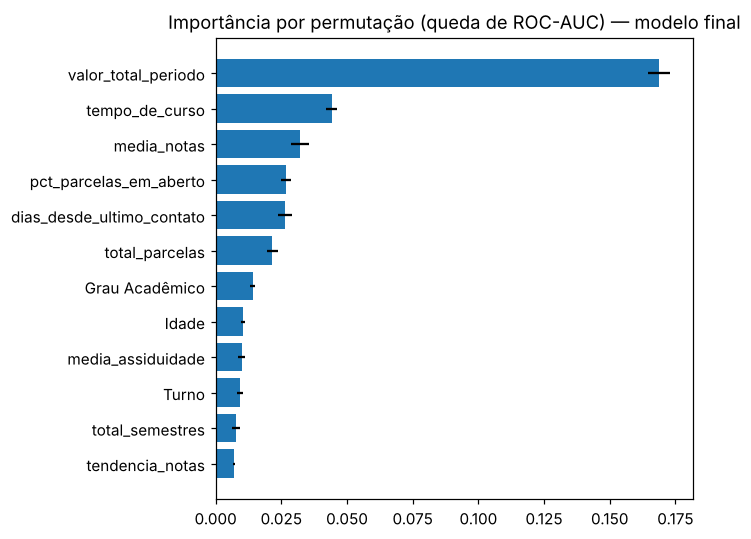

In [8]:
pi = permutation_importance(final, Xte[FEATS], yte, scoring="roc_auc", n_repeats=8, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"atributo": FEATS, "importancia_auc": pi.importances_mean, "desvio": pi.importances_std}).sort_values("importancia_auc", ascending=False)
imp.to_csv(f"{OUT}/importancia_atributos_final.csv", index=False); print(imp.head(12).round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(6.5, 5)); t = imp.head(12)[::-1]; ax.barh(t.atributo, t.importancia_auc, xerr=t.desvio)
ax.set(title="Importância por permutação (queda de ROC-AUC) — modelo final"); plt.tight_layout(); plt.savefig(f"{OUT}/importancia_atributos_final.png", dpi=140); plt.show()

Importância por permutação indica **utilidade preditiva**, não causa. Para o aluno e a equipe, a explicação operacional continua sendo a das regras da Entrega 1
(`tabela_decisao_pendencias.csv`: inadimplência, reprovação, queda de notas/assiduidade) e a evidência do agente determinístico em produção; o score só prioriza a revisão humana.

## 6. Versionamento e artefato de inferência

In [9]:
import joblib, sklearn
VERSAO = "1.0.0"
joblib.dump(final, "modelo/modelo_risco_evasao_v1.0.0.joblib", compress=3)
meta = dict(modelo="Random Forest (300 árvores, min_samples_leaf=5, class_weight=balanced_subsample)", versao=VERSAO, features=FEATS, atributos_excluidos=SENS,
            faixas=dict(verde_ate=.35, vermelho_a_partir=.65), sklearn=sklearn.__version__, semente=SEED,
            base_sha256=hashlib.sha256(open(DATA,"rb").read()).hexdigest(), n_treino=len(Xtr), n_teste=len(Xte),
            metricas_teste_limiar_050=metrics(yte, pf, .5), cv_pr_auc=float(comp.set_index("modelo").loc[FINAL,"cv_pr_auc"]), cv_roc_auc=float(comp.set_index("modelo").loc[FINAL,"cv_roc_auc"]))
json.dump(meta, open("modelo/modelo_meta_v1.0.0.json", "w"), indent=2, ensure_ascii=False, default=float)
pd.DataFrame({"y": yte.values, "score": pf, "faixa": bands.astype(str)}).to_csv(f"{OUT}/scores_teste_final.csv", index=False)
# reprodutibilidade: recarregar o artefato e conferir que os scores são idênticos
re = joblib.load("modelo/modelo_risco_evasao_v1.0.0.joblib").predict_proba(Xte[FEATS])[:, 1]
print("Scores idênticos após recarregar o artefato:", bool(np.allclose(re, pf)), "| tamanho do arquivo (MB):", round(os.path.getsize("modelo/modelo_risco_evasao_v1.0.0.joblib")/1e6, 1))
import inferencia_risco as ir
ex = Xte[FEATS].iloc[0].to_dict(); print("\nExemplo de inferência:", json.dumps(ir.pontuar(ex), ensure_ascii=False))
print("Registro incompleto (sem 'Idade' e 'Turno'):", json.dumps(ir.pontuar({k: v for k, v in ex.items() if k not in ("Idade","Turno")}), ensure_ascii=False))

Scores idênticos após recarregar o artefato: True | tamanho do arquivo (MB): 7.4

Exemplo de inferência: {"status": "scored", "score": 0.2343, "faixa": "Verde", "campos_ausentes": [], "modelo_versao": "1.0.0", "aviso": "Score de apoio à priorização; requer revisão humana. Não é decisão administrativa."}
Registro incompleto (sem 'Idade' e 'Turno'): {"status": "scored", "score": 0.421, "faixa": "Amarelo", "campos_ausentes": ["Turno", "Idade"], "modelo_versao": "1.0.0", "aviso": "Score de apoio à priorização; requer revisão humana. Não é decisão administrativa."}


## 7. Limitações de uso (resumo; versão completa no Model Card)
- Uso exclusivo de **priorização para revisão humana**. Proibido para sanção, bloqueio, reprovação, cancelamento de matrícula ou qualquer decisão automática.
- Rótulo é uma *proxy* derivada do status acadêmico; desempenho pode estar inflado por atributos acumulados que dependem de o aluno ter permanecido (seção 2).
- *Holdout* aleatório, sem separação temporal: o desempenho em um semestre futuro pode ser menor.
- Equidade avaliada só nos atributos disponíveis, com amostras pequenas em alguns grupos.
- **O score não é uma probabilidade calibrada.** Com `class_weight` balanceado o modelo superestima nas faixas intermediárias (previsto ~0,65, observado ~0,52 no teste). Use-o para ordenar e para as faixas, nunca como "X% de chance de evadir".
- As faixas de risco separam bem no conjunto de teste (taxa de evasão de 4%, 34% e 83%), mas precisam ser reavaliadas a cada semestre.
- Campos ausentes são imputados pela mediana/moda do treino e podem mudar a faixa (exemplo na seção 6: sem Idade e Turno o score foi de 0,23 para 0,42). O módulo de inferência se abstém quando mais da metade dos campos falta.